# Task 5 — Scenario Modelling

## Step 1 — Scenario Definition and Rationale

This final task builds on the previous stages of the project:

- Task 2: route generation,
- Task 3: traffic flow modelling,
- Task 4: emissions modelling.

The aim of this task is to test a realistic mobility intervention and compare its impact with the baseline case.

## Chosen Scenario: Closure of a High-Impact Cycling Corridor

The selected scenario is an intervention scenario where a high-impact cycling corridor is temporarily removed or closed from the routing network.

This scenario represents a realistic urban mobility situation, such as:

- temporary roadworks,
- construction disruption,
- street redesign,
- safety intervention,
- or a traffic management experiment.

The purpose is to understand how bicycle traffic would redistribute if an important segment or corridor became unavailable.

## Why this scenario was selected

This scenario was selected because the previous tasks already identified important corridors in the cycling network using:

- traffic flow intensity from Task 3,
- and estimated CO₂ savings from Task 4.

Instead of choosing a random road segment, the intervention will be applied to a segment or corridor that is important in the baseline model. This is necessary because closing a low-use segment would likely produce very small or uninformative changes.

## Baseline case

The baseline case represents the existing routed bicycle traffic flows generated in Task 3 and the revised emissions estimates from Task 4.

The baseline includes:

- baseline routed trips,
- baseline road-segment traffic flows,
- baseline simple emissions estimates,
- baseline revised road-attribute-based emissions estimates.

## Scenario case

In the scenario case, the selected high-impact corridor will be removed from the routing network. Routes will then be recalculated using the modified network.

After rerouting, the scenario case will include:

- scenario routes,
- scenario road-segment traffic flows,
- scenario revised emissions estimates.

## Main comparison

The main comparison will be:

$$
Baseline \; revised \; emissions \quad vs \quad Scenario \; revised \; emissions
$$

This is the fairest comparison because both are calculated using the same revised road-attribute-based emissions model.

In addition, the analysis will also compare:

$$
Baseline \; simple \; emissions \quad vs \quad Baseline \; revised \; emissions \quad vs \quad Scenario \; revised \; emissions
$$

This allows the analysis to separate:

1. the effect of improving the emissions model,
2. and the effect of the intervention scenario itself.

## Research question

The main research question is:

> How would the closure of a high-impact cycling corridor affect bicycle route redistribution, road-segment traffic flows, and estimated CO₂ savings in Jersey City and Hoboken?

## Planning relevance

This scenario is relevant for urban mobility planning because temporary closures and street redesigns can significantly affect how cyclists move through the network.

By comparing baseline and scenario results, the analysis can identify:

- which corridors lose traffic,
- which alternative routes gain traffic,
- whether bicycle flows shift to less suitable streets,
- how estimated CO₂ savings change,
- and what planning interventions may reduce negative impacts.

This makes the scenario useful for evaluating network resilience and supporting evidence-based cycling infrastructure planning.

## Step 2 — Load Libraries, Baseline Data, and Rebuild Network

This step prepares the baseline data needed for scenario modelling.

The scenario analysis builds on outputs from earlier tasks:

- Task 3 traffic flow dataset: baseline road-segment flows,
- Task 4 revised emissions dataset: baseline simple and revised CO₂ savings estimates,
- cleaned Citi Bike dataset: origin-destination trip information,
- OpenStreetMap bicycle network: used for scenario routing.

The baseline flow and emissions datasets are loaded first. Then the bicycle network for Jersey City and Hoboken is rebuilt using OSMnx. This network will later be modified to simulate the intervention scenario.

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import contextily as ctx
import osmnx as ox
import networkx as nx
from shapely.geometry import LineString
from collections import Counter
import random

In [2]:
# Load baseline traffic flows from Task 3
baseline_flow_gdf = gpd.read_file("flow_data.gpkg")

# Load revised emissions dataset from Task 4
baseline_emissions_gdf = gpd.read_file("emissions_revised_road_segments.gpkg")

# Load cleaned trip dataset
df = pd.read_csv("citi_bike_2025_cleaned_consolidated_v2.csv")

# Restore datetime columns
df["started_at"] = pd.to_datetime(df["started_at"])
df["ended_at"] = pd.to_datetime(df["ended_at"])

print("Baseline flow dataset:", baseline_flow_gdf.shape)
print("Baseline emissions dataset:", baseline_emissions_gdf.shape)
print("Cleaned trip dataset:", df.shape)

print("\nBaseline flow columns:")
print(baseline_flow_gdf.columns)

print("\nBaseline emissions columns:")
print(baseline_emissions_gdf.columns)

Baseline flow dataset: (5631, 5)
Baseline emissions dataset: (5631, 18)
Cleaned trip dataset: (962501, 17)

Baseline flow columns:
Index(['u', 'v', 'total_flow', 'length_m', 'geometry'], dtype='str')

Baseline emissions columns:
Index(['u', 'v', 'total_flow', 'length_m', 'length_km', 'highway_clean',
       'maxspeed_mph', 'final_speed_mph', 'speed_source', 'lanes_clean',
       'final_lanes', 'lane_source', 'adjusted_EF_g_per_km_v2',
       'co2_saved_kg_simple', 'co2_saved_kg_improved_v2',
       'co2_difference_kg_v2', 'co2_difference_percent_v2', 'geometry'],
      dtype='str')


In [3]:
# Rebuild the same bicycle network used in previous tasks
places = [
    "Jersey City, New Jersey, USA",
    "Hoboken, New Jersey, USA"
]

G = ox.graph_from_place(places, network_type="bike")

# Keep only the largest connected component
largest_cc = max(nx.connected_components(G.to_undirected()), key=len)
G = G.subgraph(largest_cc).copy()

print("Graph rebuilt successfully")
print("Nodes:", len(G.nodes))
print("Edges:", len(G.edges))

Graph rebuilt successfully
Nodes: 6164
Edges: 14676


In [4]:
# Check if baseline flow edges exist in the graph

baseline_flow_gdf["edge_exists_in_G"] = baseline_flow_gdf.apply(
    lambda row: G.has_edge(row["u"], row["v"]),
    axis=1
)

matched_edges = baseline_flow_gdf["edge_exists_in_G"].sum()
total_edges = len(baseline_flow_gdf)

print("Matched baseline flow edges:", matched_edges)
print("Total baseline flow edges:", total_edges)
print(f"Match rate: {(matched_edges / total_edges) * 100:.2f}%")

Matched baseline flow edges: 5631
Total baseline flow edges: 5631
Match rate: 100.00%


### Interpretation

The baseline datasets were loaded successfully.

The baseline traffic flow dataset contains 5,631 road segments, representing the edge-level bicycle traffic flows generated in Task 3. The revised emissions dataset also contains 5,631 road segments, meaning that every baseline flow segment has a corresponding emissions estimate from Task 4.

The cleaned trip dataset contains 962,501 trips and will be used to create a representative routing sample for the scenario analysis.

The OpenStreetMap bicycle network was rebuilt for Jersey City and Hoboken. The graph contains 6,164 nodes and 14,676 edges, matching the network structure used in the previous tasks.

The edge matching check shows that all 5,631 baseline flow edges exist in the rebuilt graph, giving a 100% match rate. This confirms that the baseline flow and emissions datasets are compatible with the network that will be modified for the scenario.

This validation is important because the intervention scenario will remove selected high-impact edges from this same graph and rerun routing. Since the baseline edges match the graph successfully, the scenario comparison can be performed consistently.

## Step 3 — Selecting a High-Impact Corridor for Closure

The intervention scenario requires selecting an important road segment or corridor. This is important because closing a low-flow or peripheral segment would likely produce only minimal changes in the routing and traffic flow results.

To select a meaningful intervention location, the baseline emissions dataset from Task 4 is used. Candidate corridors are identified using two indicators:

1. `total_flow`: the number of routed bicycle trips using each segment,
2. `co2_saved_kg_improved_v2`: the revised road-attribute-based CO₂ savings estimate.

Segments with high values in both indicators are considered suitable candidates because they represent locations that are important for both mobility and environmental impact.

The selected corridor will later be removed from the routing network to simulate a temporary closure, roadworks, or street intervention.

In [5]:
# ----------------------------------------------------
# Step 3A — Identify high-impact candidate segments
# ----------------------------------------------------

# Sort by highest revised CO2 savings
top_emissions_segments = baseline_emissions_gdf.nlargest(
    20, "co2_saved_kg_improved_v2"
)[
    [
        "u",
        "v",
        "total_flow",
        "length_m",
        "highway_clean",
        "final_speed_mph",
        "final_lanes",
        "adjusted_EF_g_per_km_v2",
        "co2_saved_kg_improved_v2",
        "geometry"
    ]
]

# Sort by highest traffic flow
top_flow_segments = baseline_emissions_gdf.nlargest(
    20, "total_flow"
)[
    [
        "u",
        "v",
        "total_flow",
        "length_m",
        "highway_clean",
        "final_speed_mph",
        "final_lanes",
        "adjusted_EF_g_per_km_v2",
        "co2_saved_kg_improved_v2",
        "geometry"
    ]
]

print("Top 20 segments by revised CO2 savings:")
display(top_emissions_segments.drop(columns="geometry"))

print("\nTop 20 segments by traffic flow:")
display(top_flow_segments.drop(columns="geometry"))

Top 20 segments by revised CO2 savings:


,u,v,total_flow,length_m,highway_clean,final_speed_mph,final_lanes,adjusted_EF_g_per_km_v2,co2_saved_kg_improved_v2
11,103884953,103880145,549,146.276019,secondary,20.0,2.0,303.806250,24.397323
66,103882354,103875869,491,144.211848,secondary,20.0,2.0,303.806250,21.511918
170,103867033,103867031,524,144.584839,tertiary,20.0,2.0,267.349500,20.255055
28,103878609,103869945,518,144.028744,tertiary,20.0,2.0,267.349500,19.946115
259,103870377,11309220290,365,192.295379,secondary,25.0,3.0,279.501750,19.617617
69,103868842,103886848,431,145.614978,secondary,20.0,2.0,303.806250,19.066897
68,103866348,103868842,429,145.464594,secondary,20.0,2.0,303.806250,18.958820
67,103875869,103866348,414,144.735525,secondary,20.0,2.0,303.806250,18.204225
99,4170678883,10013366190,323,251.624675,tertiary,25.0,2.0,223.601400,18.173152
250,1280340181,5391434645,365,146.056352,secondary,20.0,3.0,334.186875,17.815692



Top 20 segments by traffic flow:


,u,v,total_flow,length_m,highway_clean,final_speed_mph,final_lanes,adjusted_EF_g_per_km_v2,co2_saved_kg_improved_v2
29,103869945,103867031,606,83.439211,residential,20.0,1.0,230.892750,11.674898
30,103867031,103869947,586,46.359441,residential,20.0,1.0,249.364170,6.774385
11,103884953,103880145,549,146.276019,secondary,20.0,2.0,303.806250,24.397323
10,103865986,103884953,546,105.215688,secondary,20.0,2.0,303.806250,17.452990
171,103867031,7215123757,544,28.862349,tertiary,20.0,2.0,288.737460,4.533501
172,7215123757,103867030,544,116.233249,tertiary,20.0,2.0,267.349500,16.904746
170,103867033,103867031,524,144.584839,tertiary,20.0,2.0,267.349500,20.255055
28,103878609,103869945,518,144.028744,tertiary,20.0,2.0,267.349500,19.946115
173,103867030,103878609,512,83.788383,tertiary,20.0,1.0,253.982025,10.895740
33,103865984,103865986,501,48.171217,tertiary,20.0,2.0,288.737460,6.968326


In [6]:
# ----------------------------------------------------
# Step 3B — Create combined importance score
# ----------------------------------------------------

candidate_gdf = baseline_emissions_gdf.copy()

# Normalize total flow and revised CO2 savings between 0 and 1
candidate_gdf["flow_norm"] = (
    candidate_gdf["total_flow"] / candidate_gdf["total_flow"].max()
)

candidate_gdf["co2_norm"] = (
    candidate_gdf["co2_saved_kg_improved_v2"] /
    candidate_gdf["co2_saved_kg_improved_v2"].max()
)

# Combined score: equal weight to mobility and emissions importance
candidate_gdf["intervention_score"] = (
    0.5 * candidate_gdf["flow_norm"] +
    0.5 * candidate_gdf["co2_norm"]
)

top_candidates = candidate_gdf.nlargest(
    20, "intervention_score"
)[
    [
        "u",
        "v",
        "total_flow",
        "length_m",
        "highway_clean",
        "final_speed_mph",
        "final_lanes",
        "co2_saved_kg_improved_v2",
        "flow_norm",
        "co2_norm",
        "intervention_score",
        "geometry"
    ]
]

print("Top 20 candidate intervention segments:")
display(top_candidates.drop(columns="geometry"))

Top 20 candidate intervention segments:


,u,v,total_flow,length_m,highway_clean,final_speed_mph,final_lanes,co2_saved_kg_improved_v2,flow_norm,co2_norm,intervention_score
11,103884953,103880145,549,146.276019,secondary,20.0,2.0,24.397323,0.905941,1.000000,0.952970
170,103867033,103867031,524,144.584839,tertiary,20.0,2.0,20.255055,0.864686,0.830216,0.847451
66,103882354,103875869,491,144.211848,secondary,20.0,2.0,21.511918,0.810231,0.881733,0.845982
28,103878609,103869945,518,144.028744,tertiary,20.0,2.0,19.946115,0.854785,0.817553,0.836169
10,103865986,103884953,546,105.215688,secondary,20.0,2.0,17.452990,0.900990,0.715365,0.808178
172,7215123757,103867030,544,116.233249,tertiary,20.0,2.0,16.904746,0.897690,0.692893,0.795292
69,103868842,103886848,431,145.614978,secondary,20.0,2.0,19.066897,0.711221,0.781516,0.746369
68,103866348,103868842,429,145.464594,secondary,20.0,2.0,18.958820,0.707921,0.777086,0.742503
31,103869947,103874281,476,144.033816,service,10.0,2.0,17.041897,0.785479,0.698515,0.741997
32,103874281,103865984,473,145.906944,service,10.0,2.0,17.154720,0.780528,0.703139,0.741834


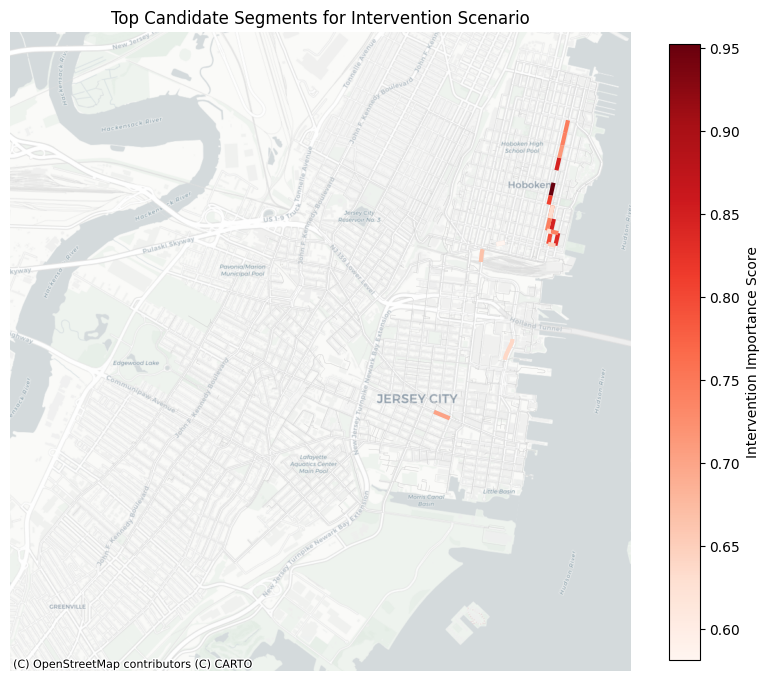

In [7]:
# ----------------------------------------------------
# Step 3C — Visualize candidate intervention segments
# ----------------------------------------------------

candidate_web = candidate_gdf.to_crs(epsg=3857)
top_candidates_web = top_candidates.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))

# Plot baseline network lightly
candidate_web.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.4,
    alpha=0.5
)

# Plot top candidate segments
top_candidates_web.plot(
    ax=ax,
    column="intervention_score",
    cmap="Reds",
    linewidth=3,
    legend=True,
    legend_kwds={
        "label": "Intervention Importance Score",
        "shrink": 0.8
    }
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Top Candidate Segments for Intervention Scenario")
ax.axis("off")

plt.show()

### Interpretation

The candidate selection process identified high-impact road segments using a combined intervention score based on normalized traffic flow and revised CO₂ savings.

The highest-ranked candidate segment has a traffic flow of 549 trips and revised CO₂ savings of approximately 24.40 kg, making it important from both mobility and environmental perspectives.

Several other high-ranking segments are located close to each other, especially in the Hoboken area. This indicates that the important segments form a corridor-like pattern rather than being isolated individual links.

This is useful for scenario modelling because closing a single very short edge may produce limited or unstable results. A corridor-level intervention, based on a small group of connected high-impact segments, is more realistic and more likely to produce observable route redistribution.

Therefore, the next step is to inspect the top candidate segment and its nearby connected edges, then define the final closure corridor for the intervention scenario.

## Step 4 — Defining the Closure Corridor

After identifying the high-impact candidate segments, the intervention corridor is defined.

The highest-ranked segment is selected as the core closure segment because it has:

- high traffic flow,
- the highest revised CO₂ savings among candidate segments,
- and a high combined intervention score.

However, closing only one OSM edge may produce very limited route changes because individual OSM edges can be short. Therefore, the intervention is defined as a small corridor-level closure by selecting the top candidate segment and nearby connected high-impact segments.

This represents a realistic temporary disruption, such as roadworks, street redesign, or a safety intervention on an important cycling corridor.

The selected closure corridor will be visualized before modifying the routing graph.

In [8]:
# ----------------------------------------------------
# Step 4A — Define closure corridor
# ----------------------------------------------------

# Select a small corridor using the highest-ranked connected / nearby candidate edges
closure_edges = [
    (103884953, 103880145),      # highest-ranked candidate
    (103865986, 103884953),      # connected upstream high-impact segment
    (103882354, 103875869),      # nearby high-impact secondary segment
    (103875869, 103866348),      # connected continuation
    (103866348, 103868842),      # connected continuation
    (103868842, 103886848)       # connected continuation
]

print("Number of closure edges:", len(closure_edges))

# Check if all closure edges exist in graph
for u, v in closure_edges:
    print(f"{u} -> {v}: exists in G =", G.has_edge(u, v))

Number of closure edges: 6
103884953 -> 103880145: exists in G = True
103865986 -> 103884953: exists in G = True
103882354 -> 103875869: exists in G = True
103875869 -> 103866348: exists in G = True
103866348 -> 103868842: exists in G = True
103868842 -> 103886848: exists in G = True


In [9]:
# ----------------------------------------------------
# Step 4B — Create GeoDataFrame for selected closure corridor
# ----------------------------------------------------

closure_rows = []

for u, v in closure_edges:
    if G.has_edge(u, v):
        edge_data = G.get_edge_data(u, v)
        first_key = list(edge_data.keys())[0]
        data = edge_data[first_key]
        
        geom = data.get("geometry", None)
        
        if geom is None:
            geom = LineString([
                (G.nodes[u]["x"], G.nodes[u]["y"]),
                (G.nodes[v]["x"], G.nodes[v]["y"])
            ])
        
        closure_rows.append({
            "u": u,
            "v": v,
            "length_m": data.get("length", None),
            "highway": data.get("highway", None),
            "geometry": geom
        })

closure_gdf = gpd.GeoDataFrame(closure_rows, crs="EPSG:4326")

print("Closure corridor segments:", len(closure_gdf))
display(closure_gdf.drop(columns="geometry"))

Closure corridor segments: 6


,u,v,length_m,highway
0,103884953,103880145,146.276019,secondary
1,103865986,103884953,105.215688,secondary
2,103882354,103875869,144.211848,secondary
3,103875869,103866348,144.735525,secondary
4,103866348,103868842,145.464594,secondary
5,103868842,103886848,145.614978,secondary


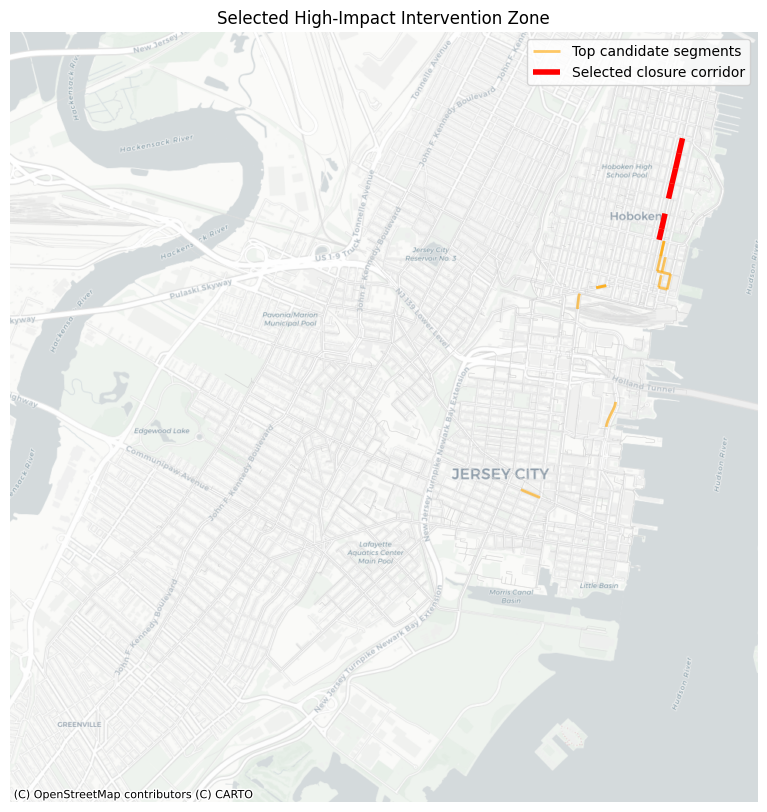

In [11]:
# ----------------------------------------------------
# Step 4C — Visualize selected closure corridor
# ----------------------------------------------------

baseline_web = baseline_emissions_gdf.to_crs(epsg=3857)
closure_web = closure_gdf.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))

# Baseline emissions network as context
baseline_web.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5,
    alpha=0.5
)

# Top candidate segments as background reference
top_candidates.to_crs(epsg=3857).plot(
    ax=ax,
    color="orange",
    linewidth=2,
    alpha=0.6,
    label="Top candidate segments"
)

# Selected closure corridor
closure_web.plot(
    ax=ax,
    color="red",
    linewidth=4,
    label="Selected closure corridor"
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Selected High-Impact Intervention Zone")
ax.axis("off")
ax.legend()

plt.show()

### Interpretation

The selected intervention area consists of 6 high-impact road segments located in Hoboken. All selected segments are classified as secondary roads, which indicates that they are relatively important connector roads within the local street network.

The selected edges were chosen from the highest-ranked candidate segments identified using the combined intervention score. This means the intervention is based on both baseline traffic flow and revised CO₂ savings, rather than being selected randomly.

The selected segments form a small high-impact closure area rather than a single isolated OSM edge. This is useful because individual OSM edges can be short, and closing only one edge may produce very limited route changes. A small corridor-level intervention is more realistic for representing temporary roadworks, construction disruption, or a street redesign project.

The selected closure area includes two nearby groups of high-impact secondary-road segments. Therefore, the scenario should be interpreted as a localized intervention zone in Hoboken, not as the closure of one continuous road segment.

This intervention area will be removed from the routing graph in the next step to test how bicycle routes, traffic flows, and estimated CO₂ savings change under the scenario.

## Step 5 — Creating the Scenario Network

In this step, the intervention scenario is implemented by creating a modified copy of the baseline bicycle network.

The original graph `G` represents the baseline road network. To preserve the baseline case, a copy of this graph is created and named `G_scenario`.

The selected high-impact intervention-zone edges are then removed from `G_scenario`. This simulates a temporary closure, roadworks, or street redesign where cyclists can no longer use those specific road segments.

The baseline graph remains unchanged, allowing a fair comparison between:

- baseline routing on the original network,
- and scenario routing on the modified network.

In [12]:
# ----------------------------------------------------
# Step 5A — Create scenario graph
# ----------------------------------------------------

# Copy the original graph so baseline remains unchanged
G_scenario = G.copy()

print("Original graph edges before closure:", len(G.edges))
print("Scenario graph edges before closure:", len(G_scenario.edges))


# ----------------------------------------------------
# Step 5B — Remove selected closure edges
# ----------------------------------------------------

removed_edges = []
not_found_edges = []

for u, v in closure_edges:
    if G_scenario.has_edge(u, v):
        # Remove all parallel edges between u and v if they exist
        keys = list(G_scenario[u][v].keys())
        for key in keys:
            G_scenario.remove_edge(u, v, key=key)
            removed_edges.append((u, v, key))
    else:
        not_found_edges.append((u, v))


print("\nEdges removed from scenario graph:", len(removed_edges))
print("Edges not found:", len(not_found_edges))

print("\nScenario graph edges after closure:", len(G_scenario.edges))

if len(not_found_edges) > 0:
    print("\nEdges not found:")
    print(not_found_edges)

Original graph edges before closure: 14676
Scenario graph edges before closure: 14676

Edges removed from scenario graph: 6
Edges not found: 0

Scenario graph edges after closure: 14670


In [13]:
# ----------------------------------------------------
# Step 5C — Validate that closure edges were removed
# ----------------------------------------------------

print("Closure edge validation:")

for u, v in closure_edges:
    print(f"{u} -> {v}: exists in baseline G = {G.has_edge(u, v)}, exists in scenario G = {G_scenario.has_edge(u, v)}")

Closure edge validation:
103884953 -> 103880145: exists in baseline G = True, exists in scenario G = False
103865986 -> 103884953: exists in baseline G = True, exists in scenario G = False
103882354 -> 103875869: exists in baseline G = True, exists in scenario G = False
103875869 -> 103866348: exists in baseline G = True, exists in scenario G = False
103866348 -> 103868842: exists in baseline G = True, exists in scenario G = False
103868842 -> 103886848: exists in baseline G = True, exists in scenario G = False


### Interpretation

The scenario network was created successfully.

The original baseline graph contained 14,676 edges. A copy of this graph was created as the scenario graph, and the selected 6 high-impact intervention-zone edges were removed from it.

After removing these edges, the scenario graph contains 14,670 edges, confirming that exactly 6 edges were removed.

The validation check confirms that each selected closure edge still exists in the baseline graph but no longer exists in the scenario graph. This means the intervention has been implemented correctly while preserving the original baseline network for comparison.

The scenario graph now represents the modified cycling network after the simulated closure. This graph will be used in the next step to reroute trips and evaluate how bicycle flows and emissions change under the intervention scenario.

## Step 6 — Rerouting Trips on the Baseline and Scenario Networks

In this step, the same representative sample of bicycle trips is routed on both the baseline network and the modified scenario network.

The baseline network (`G`) represents the original cycling network.  
The scenario network (`G_scenario`) represents the network after removing the selected high-impact intervention-zone edges.

Using the same origin-destination sample for both networks ensures that any differences in routes, route lengths, traffic flows, or emissions are caused by the intervention rather than by different input trips.

For this comparison, shortest-path routing is used on both networks. This keeps the scenario comparison controlled and interpretable.

In [14]:
# ----------------------------------------------------
# Step 6A — Create representative routing sample
# ----------------------------------------------------

# Recreate the same type of representative sample used in earlier tasks
route_sample = df.sample(100000, random_state=42).copy()
route_sample = route_sample.sample(10000, random_state=42).copy().reset_index(drop=True)

print("Routing sample size:", len(route_sample))

route_sample[
    [
        "start_lat",
        "start_lng",
        "end_lat",
        "end_lng"
    ]
].head()

Routing sample size: 10000


,start_lat,start_lng,end_lat,end_lng
0,40.735938,-74.030305,40.751889,-74.033292
1,40.736068,-74.029127,40.742659,-74.032233
2,40.744398,-74.034501,40.736810,-74.030900
3,40.743133,-74.026989,40.749985,-74.027150
4,40.747907,-74.038412,40.748716,-74.040443


In [15]:
# ----------------------------------------------------
# Step 6B — Map OD points to nearest graph nodes
# ----------------------------------------------------

# Baseline graph nodes
baseline_orig_nodes = ox.distance.nearest_nodes(
    G,
    X=route_sample["start_lng"],
    Y=route_sample["start_lat"]
)

baseline_dest_nodes = ox.distance.nearest_nodes(
    G,
    X=route_sample["end_lng"],
    Y=route_sample["end_lat"]
)

# Scenario graph nodes
scenario_orig_nodes = ox.distance.nearest_nodes(
    G_scenario,
    X=route_sample["start_lng"],
    Y=route_sample["start_lat"]
)

scenario_dest_nodes = ox.distance.nearest_nodes(
    G_scenario,
    X=route_sample["end_lng"],
    Y=route_sample["end_lat"]
)

print("Baseline origin nodes:", len(baseline_orig_nodes))
print("Baseline destination nodes:", len(baseline_dest_nodes))
print("Scenario origin nodes:", len(scenario_orig_nodes))
print("Scenario destination nodes:", len(scenario_dest_nodes))

Baseline origin nodes: 10000
Baseline destination nodes: 10000
Scenario origin nodes: 10000
Scenario destination nodes: 10000


In [16]:
# ----------------------------------------------------
# Step 6C — Helper functions
# ----------------------------------------------------

def calculate_route_length(G_input, route):
    """
    Calculate route length in meters using edge length attributes.
    """
    total_length = 0
    
    for u, v in zip(route[:-1], route[1:]):
        edge_data = G_input.get_edge_data(u, v)
        
        if edge_data is None:
            continue
        
        # If multiple edges exist, use the shortest edge length
        lengths = [
            data.get("length", 0)
            for key, data in edge_data.items()
        ]
        
        total_length += min(lengths)
    
    return total_length


def compute_shortest_routes(G_input, orig_nodes, dest_nodes):
    """
    Compute shortest-path routes and route lengths.
    """
    routes = []
    route_lengths = []
    failed_routes = 0
    
    for i, (o, d) in enumerate(zip(orig_nodes, dest_nodes)):
        try:
            route = nx.shortest_path(G_input, o, d, weight="length")
            length_m = calculate_route_length(G_input, route)
            
            routes.append(route)
            route_lengths.append(length_m)
            
        except Exception:
            routes.append(None)
            route_lengths.append(np.nan)
            failed_routes += 1
        
        if (i + 1) % 1000 == 0:
            print(f"Processed {i + 1} routes")
    
    return routes, route_lengths, failed_routes

In [17]:
# ----------------------------------------------------
# Step 6D — Compute baseline and scenario routes
# ----------------------------------------------------

print("Routing baseline network...")
baseline_routes_task5, baseline_lengths_m, baseline_failed = compute_shortest_routes(
    G,
    baseline_orig_nodes,
    baseline_dest_nodes
)

print("\nRouting scenario network...")
scenario_routes, scenario_lengths_m, scenario_failed = compute_shortest_routes(
    G_scenario,
    scenario_orig_nodes,
    scenario_dest_nodes
)

print("\nRouting completed.")
print("Baseline failed routes:", baseline_failed)
print("Scenario failed routes:", scenario_failed)

Routing baseline network...
Processed 1000 routes
Processed 2000 routes
Processed 3000 routes
Processed 4000 routes
Processed 5000 routes
Processed 6000 routes
Processed 7000 routes
Processed 8000 routes
Processed 9000 routes
Processed 10000 routes

Routing scenario network...
Processed 1000 routes
Processed 2000 routes
Processed 3000 routes
Processed 4000 routes
Processed 5000 routes
Processed 6000 routes
Processed 7000 routes
Processed 8000 routes
Processed 9000 routes
Processed 10000 routes

Routing completed.
Baseline failed routes: 0
Scenario failed routes: 0


In [18]:
# ----------------------------------------------------
# Step 6E — Route length comparison
# ----------------------------------------------------

route_comparison = pd.DataFrame({
    "baseline_length_m": baseline_lengths_m,
    "scenario_length_m": scenario_lengths_m
})

route_comparison["length_difference_m"] = (
    route_comparison["scenario_length_m"] -
    route_comparison["baseline_length_m"]
)

route_comparison["length_difference_percent"] = (
    route_comparison["length_difference_m"] /
    route_comparison["baseline_length_m"]
) * 100

print("Route length comparison summary:")
print(route_comparison.describe())

print("\nAverage baseline route length (m):", route_comparison["baseline_length_m"].mean())
print("Average scenario route length (m):", route_comparison["scenario_length_m"].mean())
print("Average length difference (m):", route_comparison["length_difference_m"].mean())
print("Average percentage difference (%):", route_comparison["length_difference_percent"].mean())

Route length comparison summary:
       baseline_length_m  scenario_length_m  length_difference_m  \
count       10000.000000       10000.000000         10000.000000   
mean         1616.665068        1623.244722             6.579653   
std           934.588696         934.898527            44.185606   
min            59.606980          59.606980             0.000000   
25%           956.461634         958.160839             0.000000   
50%          1436.057636        1462.062179             0.000000   
75%          2081.109131        2088.163286             0.000000   
max          7366.044171        7366.044171           429.721535   

       length_difference_percent  
count               10000.000000  
mean                    0.533355  
std                     4.056927  
min                     0.000000  
25%                     0.000000  
50%                     0.000000  
75%                     0.000000  
max                    90.964075  

Average baseline route length (m): 161

### Interpretation

The routing comparison shows that the intervention did not disconnect the cycling network.

All 10,000 baseline routes and all 10,000 scenario routes were successfully computed, with 0 failed routes in both cases. This means that cyclists are still able to reach their destinations after the selected intervention-zone edges are removed.

The average baseline route length is approximately 1616.67 meters, while the average scenario route length is approximately 1623.24 meters. This gives an average increase of approximately 6.58 meters, or 0.53%.

The small average increase indicates that the overall network remains resilient to this localized closure. However, the distribution shows that most trips are unaffected: the median route length difference is 0 meters, and the 75th percentile is also 0 meters.

At the same time, the maximum route length increase is approximately 429.72 meters, with a maximum percentage increase of about 90.96%. This indicates that while the intervention has limited network-wide impact, it creates substantial detours for a small number of trips that directly depend on the closed corridor.

Overall, the scenario has a localized impact rather than a system-wide disruption. This is realistic for a small corridor-level closure in a dense urban network, where many alternative routes are available nearby.

## Step 7 — Convert Baseline and Scenario Routes into Traffic Flows

After routing the same 10,000 origin-destination trips on both the baseline and scenario networks, the next step is to convert these routes into road-segment traffic flows.

Each route is broken into traversed edges. For every edge used by a route, the flow count is increased by one.

This produces two comparable flow datasets:

- `baseline_flow_task5_gdf`: traffic flows on the original baseline network,
- `scenario_flow_gdf`: traffic flows after removing the selected intervention-zone edges.

These datasets allow us to compare how bicycle traffic redistributes after the closure.

In [19]:
# ----------------------------------------------------
# Step 7A — Helper function: routes to edge flow GeoDataFrame
# ----------------------------------------------------

def routes_to_edge_flows(routes, G_input):
    """
    Convert a list of routes into an edge-level flow GeoDataFrame.
    Each route is broken into consecutive node pairs.
    Each traversed edge receives a flow count.
    """
    
    edge_counter = Counter()
    
    # Count traversed edges
    for route in routes:
        if route is None or len(route) < 2:
            continue
        
        for u, v in zip(route[:-1], route[1:]):
            edge_counter[(u, v)] += 1
    
    # Convert edge counts into GeoDataFrame
    rows = []
    
    for (u, v), flow in edge_counter.items():
        if G_input.has_edge(u, v):
            edge_data = G_input.get_edge_data(u, v)
            first_key = list(edge_data.keys())[0]
            data = edge_data[first_key]
            
            geom = data.get("geometry", None)
            
            if geom is None:
                geom = LineString([
                    (G_input.nodes[u]["x"], G_input.nodes[u]["y"]),
                    (G_input.nodes[v]["x"], G_input.nodes[v]["y"])
                ])
            
            rows.append({
                "u": u,
                "v": v,
                "flow": flow,
                "length_m": data.get("length", None),
                "geometry": geom
            })
    
    flow_result_gdf = gpd.GeoDataFrame(rows, crs="EPSG:4326")
    flow_result_gdf["length_km"] = flow_result_gdf["length_m"] / 1000
    
    return flow_result_gdf

In [20]:
# ----------------------------------------------------
# Step 7B — Create baseline and scenario flow datasets
# ----------------------------------------------------

baseline_flow_task5_gdf = routes_to_edge_flows(
    baseline_routes_task5,
    G
)

scenario_flow_gdf = routes_to_edge_flows(
    scenario_routes,
    G_scenario
)

print("Baseline Task 5 flow edges:", len(baseline_flow_task5_gdf))
print("Scenario flow edges:", len(scenario_flow_gdf))

print("\nBaseline flow statistics:")
print(baseline_flow_task5_gdf["flow"].describe())

print("\nScenario flow statistics:")
print(scenario_flow_gdf["flow"].describe())

Baseline Task 5 flow edges: 3490
Scenario flow edges: 3485

Baseline flow statistics:
count    3490.000000
mean       64.642120
std        83.376166
min         1.000000
25%         7.000000
50%        34.000000
75%        96.000000
max       609.000000
Name: flow, dtype: float64

Scenario flow statistics:
count    3485.000000
mean       65.004304
std        82.132323
min         1.000000
25%         7.000000
50%        35.000000
75%        97.000000
max       563.000000
Name: flow, dtype: float64


In [21]:
# ----------------------------------------------------
# Step 7C — Check closure edges in scenario flow
# ----------------------------------------------------

closure_check = []

for u, v in closure_edges:
    in_baseline_flow = (
        ((baseline_flow_task5_gdf["u"] == u) & (baseline_flow_task5_gdf["v"] == v)).any()
    )
    
    in_scenario_flow = (
        ((scenario_flow_gdf["u"] == u) & (scenario_flow_gdf["v"] == v)).any()
    )
    
    closure_check.append({
        "u": u,
        "v": v,
        "in_baseline_flow": in_baseline_flow,
        "in_scenario_flow": in_scenario_flow
    })

closure_check_df = pd.DataFrame(closure_check)
closure_check_df

,u,v,in_baseline_flow,in_scenario_flow
0,103884953,103880145,True,False
1,103865986,103884953,True,False
2,103882354,103875869,True,False
3,103875869,103866348,True,False
4,103866348,103868842,True,False
5,103868842,103886848,True,False


### Interpretation

The baseline and scenario routes were successfully converted into edge-level traffic flow datasets.

The baseline routing produced 3490 unique flow edges, while the scenario routing produced 3485 unique flow edges. This small difference indicates that the intervention slightly changed the set of road segments used by the routed bicycle trips.

The baseline mean flow is approximately 64.64 trips per segment, while the scenario mean flow is approximately 65.00 trips per segment. The median flow also increases slightly from 34 to 35 trips. This suggests that after the closure, traffic is redistributed across a slightly smaller set of alternative edges.

The maximum observed flow decreases from 609 in the baseline case to 563 in the scenario case. This indicates that the closure reduces traffic concentration on the most heavily used baseline segment and redistributes some trips to alternative routes.

The closure validation confirms that all six selected intervention-zone edges appear in the baseline flow dataset but do not appear in the scenario flow dataset. This means that the closure was successfully implemented and that no scenario routes use the removed edges.

Overall, the scenario does not cause a major network-wide disruption, but it produces measurable local changes in traffic flow distribution. The next step is to compare baseline and scenario flows directly to identify which segments gained or lost bicycle traffic.

## Step 8 — Baseline vs Scenario Traffic Flow Comparison

In this step, the baseline and scenario traffic flow datasets are compared.

The baseline flow dataset represents bicycle traffic on the original network. The scenario flow dataset represents bicycle traffic after the selected high-impact intervention-zone edges were removed.

To compare the two cases, the baseline and scenario flow datasets are joined using the road segment identifiers `u` and `v`.

For each road segment, the flow change is calculated as:

$$
\Delta Flow = Flow_{scenario} - Flow_{baseline}
$$

where:

- positive values indicate segments that gained traffic after the closure,
- negative values indicate segments that lost traffic,
- zero values indicate no change.

This comparison helps identify how bicycle traffic redistributes across the network after the intervention.

In [22]:
# ----------------------------------------------------
# Step 8A — Prepare baseline and scenario flow tables
# ----------------------------------------------------

baseline_compare = baseline_flow_task5_gdf[
    ["u", "v", "flow", "length_m", "length_km", "geometry"]
].copy()

baseline_compare = baseline_compare.rename(columns={
    "flow": "baseline_flow",
    "length_m": "baseline_length_m",
    "length_km": "baseline_length_km",
    "geometry": "baseline_geometry"
})

scenario_compare = scenario_flow_gdf[
    ["u", "v", "flow", "length_m", "length_km", "geometry"]
].copy()

scenario_compare = scenario_compare.rename(columns={
    "flow": "scenario_flow",
    "length_m": "scenario_length_m",
    "length_km": "scenario_length_km",
    "geometry": "scenario_geometry"
})

print("Baseline comparison table:", baseline_compare.shape)
print("Scenario comparison table:", scenario_compare.shape)

Baseline comparison table: (3490, 6)
Scenario comparison table: (3485, 6)


In [23]:
# ----------------------------------------------------
# Step 8B — Merge baseline and scenario flows
# ----------------------------------------------------

flow_comparison = baseline_compare.merge(
    scenario_compare,
    on=["u", "v"],
    how="outer"
)

# Fill missing flows with 0
flow_comparison["baseline_flow"] = flow_comparison["baseline_flow"].fillna(0)
flow_comparison["scenario_flow"] = flow_comparison["scenario_flow"].fillna(0)

# Use available geometry
flow_comparison["geometry"] = flow_comparison["baseline_geometry"]

flow_comparison["geometry"] = flow_comparison["geometry"].where(
    flow_comparison["geometry"].notna(),
    flow_comparison["scenario_geometry"]
)

# Use available length
flow_comparison["length_m"] = flow_comparison["baseline_length_m"]

flow_comparison["length_m"] = flow_comparison["length_m"].where(
    flow_comparison["length_m"].notna(),
    flow_comparison["scenario_length_m"]
)

flow_comparison["length_km"] = flow_comparison["length_m"] / 1000

# Calculate flow difference
flow_comparison["flow_difference"] = (
    flow_comparison["scenario_flow"] - flow_comparison["baseline_flow"]
)

flow_comparison["abs_flow_difference"] = flow_comparison["flow_difference"].abs()

# Convert to GeoDataFrame
flow_comparison_gdf = gpd.GeoDataFrame(
    flow_comparison.drop(columns=["baseline_geometry", "scenario_geometry"]),
    geometry="geometry",
    crs="EPSG:4326"
)

print("Flow comparison edges:", len(flow_comparison_gdf))

print("\nFlow difference summary:")
print(flow_comparison_gdf["flow_difference"].describe())

flow_comparison_gdf[
    ["u", "v", "baseline_flow", "scenario_flow", "flow_difference"]
].head()

Flow comparison edges: 3493

Flow difference summary:
count    3493.000000
mean        0.268823
std        30.653416
min      -599.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       376.000000
Name: flow_difference, dtype: float64


,u,v,baseline_flow,scenario_flow,flow_difference
0,60007643,6057092406,12.0,12.0,0.0
1,60007643,6057111314,101.0,101.0,0.0
2,60007644,10853963155,89.0,89.0,0.0
3,60007644,12814428730,217.0,217.0,0.0
4,103855169,103863030,14.0,14.0,0.0


In [24]:
# ----------------------------------------------------
# Step 8C — Summarize gained and lost traffic
# ----------------------------------------------------

lost_edges = flow_comparison_gdf[flow_comparison_gdf["flow_difference"] < 0]
gained_edges = flow_comparison_gdf[flow_comparison_gdf["flow_difference"] > 0]
unchanged_edges = flow_comparison_gdf[flow_comparison_gdf["flow_difference"] == 0]

print("Edges that lost traffic:", len(lost_edges))
print("Edges that gained traffic:", len(gained_edges))
print("Edges unchanged:", len(unchanged_edges))

print("\nTotal flow lost:", lost_edges["flow_difference"].sum())
print("Total flow gained:", gained_edges["flow_difference"].sum())

print("\nTop 10 edges with largest traffic loss:")
display(
    lost_edges.nsmallest(10, "flow_difference")[
        ["u", "v", "baseline_flow", "scenario_flow", "flow_difference"]
    ]
)

print("\nTop 10 edges with largest traffic gain:")
display(
    gained_edges.nlargest(10, "flow_difference")[
        ["u", "v", "baseline_flow", "scenario_flow", "flow_difference"]
    ]
)

Edges that lost traffic: 77
Edges that gained traffic: 104
Edges unchanged: 3312

Total flow lost: -6015.0
Total flow gained: 6954.0

Top 10 edges with largest traffic loss:


,u,v,baseline_flow,scenario_flow,flow_difference
634,103865986,103884953,599.0,0.0,-599.0
2145,103884953,103880145,599.0,0.0,-599.0
2031,103882354,103875869,505.0,0.0,-505.0
630,103865984,103865986,544.0,90.0,-454.0
695,103866348,103868842,441.0,0.0,-441.0
1064,103868842,103886848,441.0,0.0,-441.0
1619,103875869,103866348,412.0,0.0,-412.0
1871,103880145,103882354,318.0,0.0,-318.0
1383,103872682,103882354,187.0,0.0,-187.0
2171,103886848,305556451,436.0,278.0,-158.0



Top 10 edges with largest traffic gain:


,u,v,baseline_flow,scenario_flow,flow_difference
1384,103872684,103866350,6.0,382.0,376.0
90,103859251,103880145,42.0,398.0,356.0
632,103865984,6804047357,45.0,401.0,356.0
1995,103881927,103859251,0.0,356.0,356.0
2905,6804047357,103881927,45.0,401.0,356.0
1382,103872682,103872684,151.0,478.0,327.0
1386,103872686,103886848,22.0,305.0,283.0
698,103866350,103868843,6.0,284.0,278.0
1065,103868843,103872686,6.0,284.0,278.0
1380,103872680,103872682,163.0,358.0,195.0


### Visual Comparison of Baseline and Scenario Flows

The following maps compare traffic flows before and after the intervention.

The first map shows the baseline traffic flow on the original network.  
The second map shows the scenario traffic flow after the selected intervention-zone edges were removed.

The same color scale is used for both maps to make the comparison visible.

C:\Users\BULAND KUMAR PRADHAN\AppData\Local\Temp\ipykernel_21388\4119228253.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


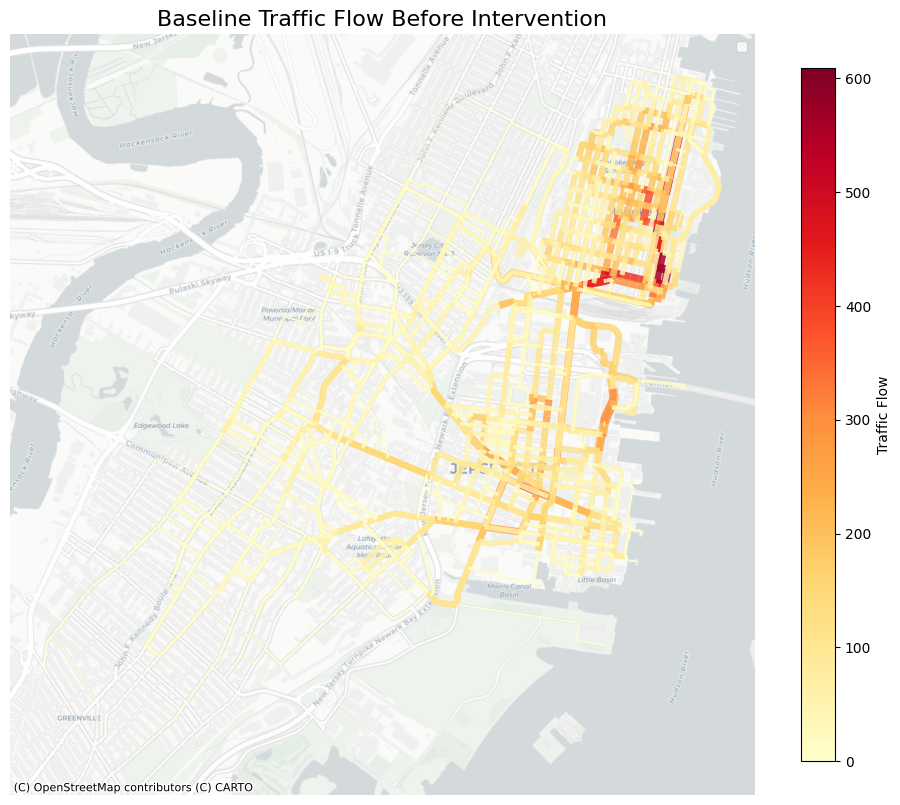

In [32]:
# ----------------------------------------------------
# Step 8D-1 — Large baseline traffic flow map
# ----------------------------------------------------

baseline_web = baseline_flow_task5_gdf.to_crs(epsg=3857)
scenario_web = scenario_flow_gdf.to_crs(epsg=3857)

# Same color scale for both baseline and scenario
vmax_flow = max(
    baseline_web["flow"].max(),
    scenario_web["flow"].max()
)

fig, ax = plt.subplots(figsize=(12, 12))

baseline_web.plot(
    ax=ax,
    column="flow",
    cmap="YlOrRd",
    linewidth=np.log1p(baseline_web["flow"]) * 0.9 + 0.2,
    alpha=0.85,
    vmin=0,
    vmax=vmax_flow,
    legend=True,
    legend_kwds={
        "label": "Traffic Flow",
        "shrink": 0.75
    }
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Baseline Traffic Flow Before Intervention", fontsize=16)
ax.axis("off")
ax.legend()

plt.show()

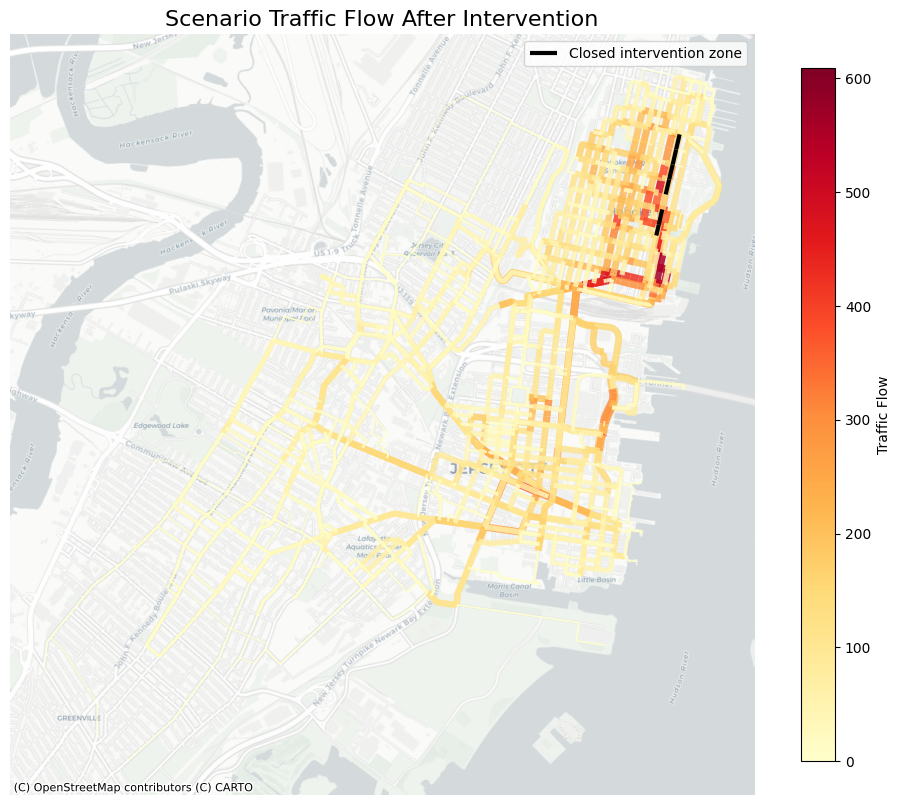

In [33]:
# ----------------------------------------------------
# Step 8D-2 — Large scenario traffic flow map
# ----------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 12))

scenario_web.plot(
    ax=ax,
    column="flow",
    cmap="YlOrRd",
    linewidth=np.log1p(scenario_web["flow"]) * 0.9 + 0.2,
    alpha=0.85,
    vmin=0,
    vmax=vmax_flow,
    legend=True,
    legend_kwds={
        "label": "Traffic Flow",
        "shrink": 0.75
    }
)

# Show closure zone for reference
closure_gdf.to_crs(epsg=3857).plot(
    ax=ax,
    color="black",
    linewidth=3,
    label="Closed intervention zone"
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Scenario Traffic Flow After Intervention", fontsize=16)
ax.axis("off")
ax.legend()

plt.show()

### Traffic Flow Difference Map

The difference map shows how traffic changes after the intervention.

$$
\Delta Flow = Flow_{scenario} - Flow_{baseline}
$$

- Red segments indicate traffic increases in the scenario.
- Blue segments indicate traffic decreases in the scenario.
- Segments close to zero show little or no change.

This map is the most important visualization for identifying rerouting effects.

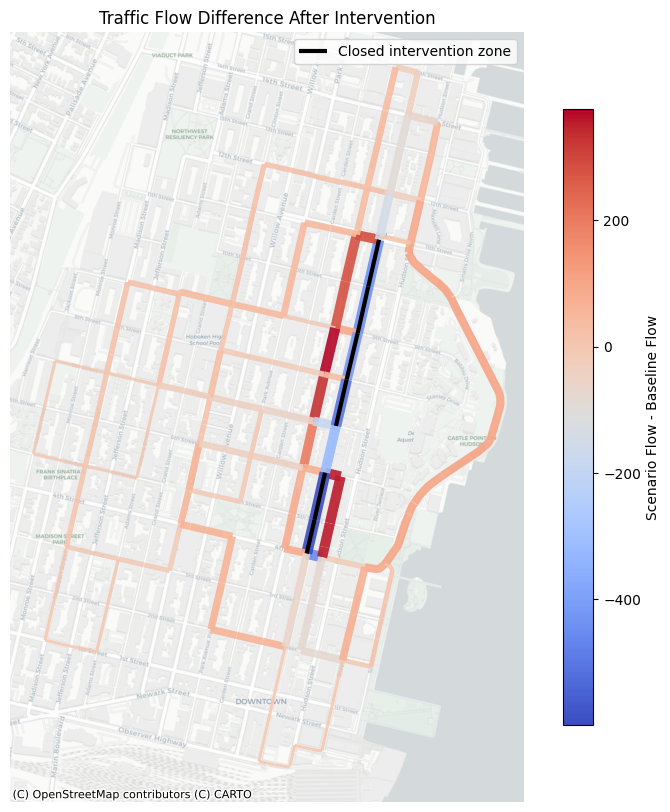

In [26]:
# ----------------------------------------------------
# Step 8E — Flow difference map
# ----------------------------------------------------

flow_diff_web = flow_comparison_gdf.to_crs(epsg=3857)

# Keep only changed edges for clearer visualization
changed_flow_web = flow_diff_web[flow_diff_web["flow_difference"] != 0].copy()

fig, ax = plt.subplots(figsize=(10, 10))

changed_flow_web.plot(
    ax=ax,
    column="flow_difference",
    cmap="coolwarm",
    linewidth=np.log1p(changed_flow_web["abs_flow_difference"]) * 1.2 + 0.3,
    alpha=0.9,
    legend=True,
    legend_kwds={
        "label": "Scenario Flow - Baseline Flow",
        "shrink": 0.8
    }
)

# Highlight closure corridor
closure_gdf.to_crs(epsg=3857).plot(
    ax=ax,
    color="black",
    linewidth=3,
    label="Closed intervention zone"
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Traffic Flow Difference After Intervention")
ax.axis("off")
ax.legend()

plt.show()

### Interpretation

The baseline map shows the original distribution of bicycle traffic across the network. The scenario map shows the redistributed flows after the selected intervention-zone edges were removed.

The overall spatial pattern remains broadly similar, which is expected because the intervention is localized and the surrounding urban street network provides several alternative routes. However, the closure causes measurable local redistribution.

The flow comparison shows that 77 edges lost traffic, 104 edges gained traffic, and 3312 edges remained unchanged. This confirms that the intervention affects only part of the network rather than causing a system-wide disruption.

The largest losses occur on the closed intervention-zone edges and nearby connected segments. The largest gains occur on alternative routes around the closure, showing how cyclists are rerouted through nearby parallel or connecting streets.

The total gained edge-flow count is higher than the total lost edge-flow count because some scenario routes become slightly longer and therefore traverse more road segments. This is consistent with the route-length analysis, which showed a small average increase in route length after the intervention.

Overall, the intervention produces a localized redistribution effect. The network remains connected and resilient, but the closure shifts traffic to nearby alternative corridors.

## Step 9 — Comparing Baseline and Scenario Emissions

After comparing traffic flow changes, the next step is to evaluate how the intervention affects estimated CO₂ savings.

This comparison includes three emissions estimates:

1. Baseline simple emissions model  
   This is the original Task 4 model using a constant weighted emission factor.

2. Baseline revised emissions model  
   This is the improved Task 4 model using road-attribute-based emission factors.

3. Scenario revised emissions model  
   This applies the same revised emissions model to the scenario traffic flows after the intervention.

The most important comparison is between:

$$
Baseline \; revised \; emissions
$$

and

$$
Scenario \; revised \; emissions
$$

because both are calculated using the same road-attribute-based emissions framework. This makes the comparison fair and isolates the effect of the intervention.

In [35]:
# ----------------------------------------------------
# Step 9A — Attach road attributes to scenario flow edges
# ----------------------------------------------------

# Use Task 4 revised emissions dataset as attribute reference
attribute_cols = [
    "u",
    "v",
    "highway_clean",
    "final_speed_mph",
    "speed_source",
    "final_lanes",
    "lane_source",
    "adjusted_EF_g_per_km_v2"
]

scenario_emissions_gdf = scenario_flow_gdf.merge(
    baseline_emissions_gdf[attribute_cols],
    on=["u", "v"],
    how="left"
)

print("Scenario emissions dataset after attribute merge:")
print(scenario_emissions_gdf.shape)

print("\nMissing adjusted EF values:")
print(scenario_emissions_gdf["adjusted_EF_g_per_km_v2"].isna().sum())

scenario_emissions_gdf.head()

Scenario emissions dataset after attribute merge:
(3485, 12)

Missing adjusted EF values:
19


,u,v,flow,length_m,geometry,length_km,highway_clean,final_speed_mph,speed_source,final_lanes,lane_source,adjusted_EF_g_per_km_v2
0,5451987123,297110085,235,46.263959,"LINESTRING (-74.03022 40.73586, -74.03032 40.7...",0.046264,tertiary,20.0,observed_from_OSM,2.0,imputed_from_highway_and_speed,288.737460
1,297110085,297110097,218,46.277329,"LINESTRING (-74.03037 40.73546, -74.03038 40.7...",0.046277,tertiary,20.0,observed_from_OSM,2.0,observed_from_OSM,288.737460
2,297110097,7217917595,218,20.824373,"LINESTRING (-74.0309 40.73551, -74.03115 40.73...",0.020824,tertiary,20.0,observed_from_OSM,2.0,observed_from_OSM,307.451925
3,7217917595,103866250,218,26.904055,"LINESTRING (-74.03115 40.73555, -74.03128 40.7...",0.026904,tertiary,20.0,observed_from_OSM,3.0,observed_from_OSM,317.611206
4,103866250,4988900669,64,34.830991,"LINESTRING (-74.03146 40.73561, -74.03143 40.7...",0.034831,secondary,20.0,observed_from_OSM,3.0,observed_from_OSM,360.921825


### Handling New Scenario Edges

After merging the scenario flow dataset with the baseline emissions dataset, 19 scenario edges had missing adjusted emission factors.

This happened because the intervention caused some routes to shift onto road segments that were not used in the baseline emissions dataset. Since these edges did not appear in the Task 4 baseline emissions output, their road-attribute-based emission factors were not already available.

To handle this, the same revised Task 4 emissions logic is applied to these new scenario edges:

- extract road attributes from the scenario graph,
- clean road type, speed, and lane values,
- fill missing speed and lane values using road-type assumptions,
- calculate the adjusted emission factor using the same road type, speed, lane, and interruption factors.

This ensures that scenario emissions are calculated consistently for all edges, including newly used rerouting segments.

In [37]:
# ----------------------------------------------------
# Base emission factor from revised Task 4 model
# ----------------------------------------------------

EF_WEIGHTED = 220.95  # g CO2 per km

print("Base weighted emission factor:", EF_WEIGHTED, "g CO2/km")

Base weighted emission factor: 220.95 g CO2/km


In [38]:
# ----------------------------------------------------
# Step 9B — Fill missing adjusted EF values for new scenario edges
# ----------------------------------------------------

import re

def get_edge_data_safe(G_input, u, v):
    """Return first edge data between u and v, if available."""
    try:
        edge_data = G_input.get_edge_data(u, v)
        if edge_data is None:
            return {}
        first_key = list(edge_data.keys())[0]
        return edge_data[first_key]
    except:
        return {}


def clean_highway_value(value):
    """Clean highway value; if list, take first value."""
    if isinstance(value, list):
        return value[0]
    return value


def clean_speed_value(value):
    """Convert maxspeed values such as '20 mph' into numeric mph."""
    if isinstance(value, list):
        value = value[0]
    if pd.isna(value):
        return np.nan
    
    numbers = re.findall(r"\d+", str(value))
    if len(numbers) > 0:
        return float(numbers[0])
    return np.nan


def clean_lane_value(value):
    """Convert lane values into numeric form."""
    if isinstance(value, list):
        value = value[0]
    if pd.isna(value):
        return np.nan
    try:
        return float(value)
    except:
        return np.nan


# Fallback values, same logic as revised Task 4
fallback_speed_by_highway = {
    "trunk": 35,
    "trunk_link": 30,
    "primary": 30,
    "primary_link": 25,
    "secondary": 25,
    "secondary_link": 20,
    "tertiary": 20,
    "tertiary_link": 20,
    "residential": 20,
    "service": 15,
    "unclassified": 20,
    "pedestrian": 10,
    "cycleway": 10,
    "path": 10
}

fallback_lanes_by_highway = {
    "trunk": 4,
    "trunk_link": 2,
    "primary": 3,
    "primary_link": 2,
    "secondary": 2,
    "secondary_link": 2,
    "tertiary": 2,
    "tertiary_link": 1,
    "residential": 1,
    "service": 1,
    "unclassified": 1,
    "pedestrian": 1,
    "cycleway": 1,
    "path": 1
}

road_type_factor_v2 = {
    "trunk": 1.45,
    "trunk_link": 1.35,
    "primary": 1.35,
    "primary_link": 1.25,
    "secondary": 1.25,
    "secondary_link": 1.15,
    "tertiary": 1.10,
    "tertiary_link": 1.05,
    "residential": 1.00,
    "service": 0.90,
    "unclassified": 0.95,
    "pedestrian": 0.70,
    "cycleway": 0.65,
    "path": 0.65
}


def speed_factor_v2(speed):
    if speed <= 10:
        return 1.25
    elif speed <= 15:
        return 1.18
    elif speed <= 20:
        return 1.10
    elif speed <= 30:
        return 1.00
    else:
        return 1.12


def lane_factor_v2(lanes):
    if lanes <= 1:
        return 0.95
    elif lanes == 2:
        return 1.00
    elif lanes == 3:
        return 1.10
    else:
        return 1.20


def interruption_factor_v2(length_m):
    if length_m <= 25:
        return 1.15
    elif length_m <= 75:
        return 1.08
    elif length_m <= 150:
        return 1.00
    elif length_m <= 300:
        return 0.92
    else:
        return 0.85


def calculate_adjusted_ef_for_scenario_edge(row):
    """
    Calculate adjusted EF for scenario edges missing Task 4 baseline EF.
    Uses the same revised Task 4 logic.
    """
    u = row["u"]
    v = row["v"]
    
    data = get_edge_data_safe(G_scenario, u, v)
    
    highway = clean_highway_value(data.get("highway", None))
    maxspeed = clean_speed_value(data.get("maxspeed", np.nan))
    lanes = clean_lane_value(data.get("lanes", np.nan))
    
    # Fill missing values using road-type fallback
    if pd.isna(maxspeed):
        maxspeed = fallback_speed_by_highway.get(highway, 20)
    
    if pd.isna(lanes):
        lanes = fallback_lanes_by_highway.get(highway, 1)
    
    road_factor = road_type_factor_v2.get(highway, 1.00)
    speed_factor = speed_factor_v2(maxspeed)
    lane_factor = lane_factor_v2(lanes)
    interruption_factor = interruption_factor_v2(row["length_m"])
    
    adjusted_ef = (
        EF_WEIGHTED *
        road_factor *
        speed_factor *
        lane_factor *
        interruption_factor
    )
    
    # Same cap as Task 4
    adjusted_ef = min(max(adjusted_ef, 100), 450)
    
    return pd.Series({
        "highway_clean": highway,
        "final_speed_mph": maxspeed,
        "speed_source": "scenario_edge_assumed_or_extracted",
        "final_lanes": lanes,
        "lane_source": "scenario_edge_assumed_or_extracted",
        "adjusted_EF_g_per_km_v2": adjusted_ef
    })


# Identify missing EF rows
missing_ef_mask = scenario_emissions_gdf["adjusted_EF_g_per_km_v2"].isna()

print("Missing EF before filling:", missing_ef_mask.sum())

# Calculate missing attributes and EF
filled_missing_values = scenario_emissions_gdf[missing_ef_mask].apply(
    calculate_adjusted_ef_for_scenario_edge,
    axis=1
)

# Fill missing values back into scenario_emissions_gdf
for col in filled_missing_values.columns:
    scenario_emissions_gdf.loc[missing_ef_mask, col] = filled_missing_values[col].values

print("Missing EF after filling:", scenario_emissions_gdf["adjusted_EF_g_per_km_v2"].isna().sum())

# Preview newly filled scenario edges
scenario_emissions_gdf.loc[
    missing_ef_mask,
    [
        "u",
        "v",
        "flow",
        "length_m",
        "highway_clean",
        "final_speed_mph",
        "final_lanes",
        "adjusted_EF_g_per_km_v2"
    ]
]

Missing EF before filling: 19
Missing EF after filling: 0


,u,v,flow,length_m,highway_clean,final_speed_mph,final_lanes,adjusted_EF_g_per_km_v2
3345,103862937,103873651,1,174.451465,residential,20.0,1.0,212.42133
3346,103873651,103873649,1,150.726463,residential,20.0,1.0,212.42133
3347,103873649,103864632,1,91.935245,residential,20.0,1.0,230.89275
3348,103864632,103873648,1,93.589822,residential,20.0,1.0,230.89275
3349,103873648,103873646,1,93.151864,residential,20.0,1.0,230.89275
3350,103873646,103869326,1,94.382857,residential,20.0,1.0,230.89275
3369,103876006,103882267,1,174.250074,residential,20.0,1.0,212.42133
3370,3984696714,103882911,1,110.107362,secondary,25.0,2.0,276.18750
3371,103882911,103879167,1,74.758808,secondary,25.0,2.0,298.28250
3372,103879167,103865500,1,74.539618,secondary,25.0,2.0,298.28250


### Interpretation

After merging the scenario flow dataset with the baseline revised emissions dataset, 19 scenario edges had missing adjusted emission factors.

These missing values occurred because the intervention caused some trips to reroute onto road segments that were not used in the baseline emissions dataset. Since those edges were not present in the baseline Task 4 emissions output, their road-attribute-based emission factors had to be calculated separately.

The missing emission factors were filled using the same revised emissions logic developed in Task 4. Road attributes were extracted from the scenario graph, missing speed and lane values were filled using road-type assumptions, and the adjusted emission factor was calculated using road type, speed, lane count, and interruption factors.

After this step, the number of missing adjusted emission factors was reduced from 19 to 0. This means that all scenario flow edges now have valid emission factors and can be used for scenario emissions calculation.

The newly filled values are consistent with the revised model: residential segments generally receive lower emission factors, while secondary road segments receive higher emission factors.

In [39]:
# ----------------------------------------------------
# Step 9C — Calculate scenario revised CO2 savings
# ----------------------------------------------------

scenario_emissions_gdf["co2_saved_kg_scenario_revised"] = (
    scenario_emissions_gdf["flow"]
    * scenario_emissions_gdf["length_km"]
    * scenario_emissions_gdf["adjusted_EF_g_per_km_v2"]
    / 1000
)

print("Scenario revised emissions summary:")
print(scenario_emissions_gdf["co2_saved_kg_scenario_revised"].describe())

scenario_revised_total = scenario_emissions_gdf["co2_saved_kg_scenario_revised"].sum()

print("\nTotal scenario revised CO2 saved:")
print(f"{scenario_revised_total:.2f} kg")

Scenario revised emissions summary:
count    3485.000000
mean        1.246404
std         2.040525
min         0.000710
25%         0.101079
50%         0.496910
75%         1.479009
max        21.414695
Name: co2_saved_kg_scenario_revised, dtype: float64

Total scenario revised CO2 saved:
4343.72 kg


In [41]:
# ----------------------------------------------------
# Step 9D — Clean comparison table without NaN
# ----------------------------------------------------

baseline_simple_total = baseline_emissions_gdf["co2_saved_kg_simple"].sum()
baseline_revised_total = baseline_emissions_gdf["co2_saved_kg_improved_v2"].sum()
scenario_revised_total = scenario_emissions_gdf["co2_saved_kg_scenario_revised"].sum()

emissions_comparison_table = pd.DataFrame({
    "Model": [
        "Baseline simple model",
        "Baseline revised model",
        "Scenario revised model"
    ],
    "Description": [
        "Constant weighted emission factor",
        "Road-attribute-based emission factor",
        "Intervention scenario with road-attribute-based emission factor"
    ],
    "Total_CO2_saved_kg": [
        baseline_simple_total,
        baseline_revised_total,
        scenario_revised_total
    ]
})

# Calculate differences
emissions_comparison_table["Difference_from_previous_kg"] = (
    emissions_comparison_table["Total_CO2_saved_kg"].diff()
)

emissions_comparison_table["Difference_from_previous_percent"] = (
    emissions_comparison_table["Difference_from_previous_kg"]
    / emissions_comparison_table["Total_CO2_saved_kg"].shift(1)
    * 100
)

# Replace NaN in first row with 0
emissions_comparison_table["Difference_from_previous_kg"] = (
    emissions_comparison_table["Difference_from_previous_kg"].fillna(0)
)

emissions_comparison_table["Difference_from_previous_percent"] = (
    emissions_comparison_table["Difference_from_previous_percent"].fillna(0)
)

# Round values for cleaner display
emissions_comparison_table["Total_CO2_saved_kg"] = emissions_comparison_table["Total_CO2_saved_kg"].round(2)
emissions_comparison_table["Difference_from_previous_kg"] = emissions_comparison_table["Difference_from_previous_kg"].round(2)
emissions_comparison_table["Difference_from_previous_percent"] = emissions_comparison_table["Difference_from_previous_percent"].round(2)

emissions_comparison_table

,Model,Description,Total_CO2_saved_kg,Difference_from_previous_kg,Difference_from_previous_percent
0,Baseline simple model,Constant weighted emission factor,3737.27,0.00,0.00
1,Baseline revised model,Road-attribute-based emission factor,4518.61,781.35,20.91
2,Scenario revised model,Intervention scenario with road-attribute-base...,4343.72,-174.89,-3.87


### Interpretation

The emissions comparison separates the effect of improving the emissions model from the effect of the scenario intervention.

The baseline simple model estimates total CO₂ savings of approximately 3737.27 kg using a constant weighted emission factor.

The baseline revised model estimates total CO₂ savings of approximately 4518.61 kg using the road-attribute-based emissions model developed in Task 4. This is 781.35 kg higher than the simple baseline model, corresponding to an increase of approximately 20.91%. This difference reflects the methodological improvement from using road-specific emission factors instead of a single constant factor.

The scenario revised model estimates total CO₂ savings of approximately 4343.72 kg after the intervention. Compared with the baseline revised model, this is a decrease of approximately 174.89 kg, or 3.87%.

The most important comparison is between the baseline revised model and the scenario revised model because both use the same road-attribute-based emissions framework. This comparison shows the actual effect of the intervention.

The decrease in CO₂ savings suggests that the closure slightly reduces the environmental benefit of the observed bicycle trips. This may occur because some cyclists are rerouted onto alternative paths with different road characteristics and slightly longer travel distances.

However, the reduction is relatively small, indicating that the network remains fairly resilient. The intervention creates localized traffic redistribution and a modest emissions impact rather than a major system-wide disruption.

### Emissions Maps — Baseline Revised vs Scenario Revised

The emissions comparison table shows the total estimated CO₂ savings under three models. To understand where these changes occur spatially, the baseline revised emissions and scenario revised emissions are mapped.

The baseline revised emissions map uses the road-attribute-based emissions model from Task 4.

The scenario revised emissions map uses the same road-attribute-based emissions model, but applies it to the traffic flows after the intervention.

The same color scale is used for both maps so that the baseline and scenario results can be compared fairly.

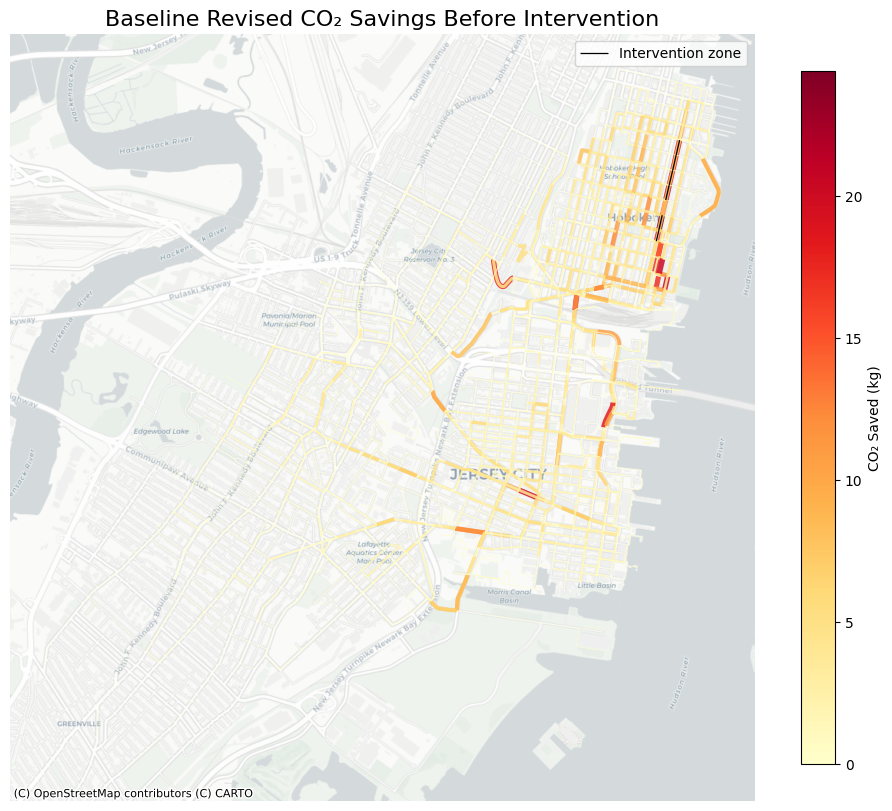

In [46]:
# ----------------------------------------------------
# Step 9E-1 — Baseline revised emissions map
# ----------------------------------------------------

baseline_emissions_web = baseline_emissions_gdf.to_crs(epsg=3857)
scenario_emissions_web = scenario_emissions_gdf.to_crs(epsg=3857)

# Same scale for baseline and scenario maps
vmax_emissions = max(
    baseline_emissions_web["co2_saved_kg_improved_v2"].max(),
    scenario_emissions_web["co2_saved_kg_scenario_revised"].max()
)

fig, ax = plt.subplots(figsize=(12, 12))

baseline_emissions_web.plot(
    ax=ax,
    column="co2_saved_kg_improved_v2",
    cmap="YlOrRd",
    linewidth=np.log1p(baseline_emissions_web["co2_saved_kg_improved_v2"]) * 1.2 + 0.2,
    alpha=0.85,
    vmin=0,
    vmax=vmax_emissions,
    legend=True,
    legend_kwds={
        "label": "CO₂ Saved (kg)",
        "shrink": 0.75
    }
)

closure_gdf.to_crs(epsg=3857).plot(
    ax=ax,
    color="black",
    linewidth=0.9,
    label="Intervention zone"
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Baseline Revised CO₂ Savings Before Intervention", fontsize=16)
ax.axis("off")
ax.legend()

plt.show()

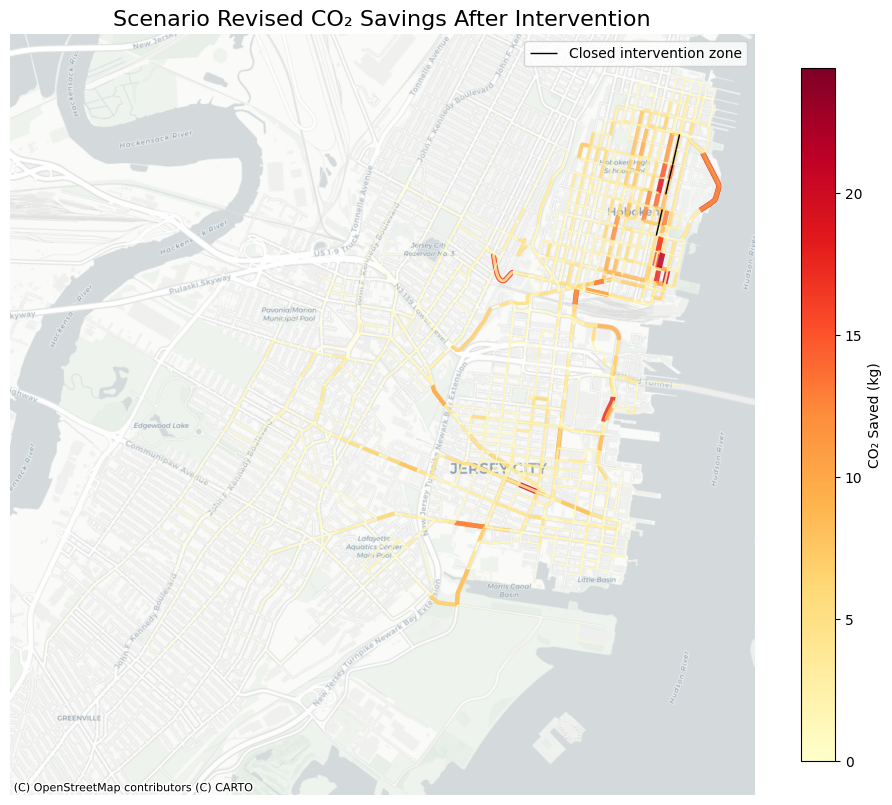

In [45]:
# ----------------------------------------------------
# Step 9E-2 — Scenario revised emissions map
# ----------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 12))

scenario_emissions_web.plot(
    ax=ax,
    column="co2_saved_kg_scenario_revised",
    cmap="YlOrRd",
    linewidth=np.log1p(scenario_emissions_web["co2_saved_kg_scenario_revised"]) * 1.2 + 0.2,
    alpha=0.85,
    vmin=0,
    vmax=vmax_emissions,
    legend=True,
    legend_kwds={
        "label": "CO₂ Saved (kg)",
        "shrink": 0.75
    }
)

closure_gdf.to_crs(epsg=3857).plot(
    ax=ax,
    color="black",
    linewidth=1,
    label="Closed intervention zone"
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Scenario Revised CO₂ Savings After Intervention", fontsize=16)
ax.axis("off")
ax.legend()

plt.show()

### Interpretation

The baseline revised emissions map shows the estimated CO₂ savings under the original network conditions using the road-attribute-based emissions model from Task 4.

The scenario revised emissions map shows the estimated CO₂ savings after the selected intervention-zone edges were removed and trips were rerouted.

The broad spatial pattern remains similar because most trips are not strongly affected by the localized closure. However, the scenario map reflects the removal of emissions savings from the closed intervention zone and redistribution to nearby alternative routes.

The intervention does not create a major network-wide emissions change, but it does produce localized shifts in where emissions savings occur.

### Emissions Difference Map — Scenario Revised Minus Baseline Revised

To identify where the intervention changes estimated CO₂ savings, an emissions difference map is created.

The difference is calculated as:

$$
\Delta CO₂ = CO₂_{scenario\ revised} - CO₂_{baseline\ revised}
$$

where:

- positive values indicate road segments where CO₂ savings increased in the scenario,
- negative values indicate road segments where CO₂ savings decreased in the scenario,
- values close to zero indicate little or no change.

This map helps identify how the closure redistributes environmental benefits across the network.

In [47]:
# ----------------------------------------------------
# Step 9F — Emissions difference map
# Scenario revised emissions - Baseline revised emissions
# ----------------------------------------------------

# Prepare baseline emissions table
baseline_emissions_compare = baseline_emissions_gdf[
    ["u", "v", "co2_saved_kg_improved_v2", "geometry"]
].copy()

baseline_emissions_compare = baseline_emissions_compare.rename(columns={
    "co2_saved_kg_improved_v2": "baseline_revised_co2_kg",
    "geometry": "baseline_geometry"
})

# Prepare scenario emissions table
scenario_emissions_compare = scenario_emissions_gdf[
    ["u", "v", "co2_saved_kg_scenario_revised", "geometry"]
].copy()

scenario_emissions_compare = scenario_emissions_compare.rename(columns={
    "co2_saved_kg_scenario_revised": "scenario_revised_co2_kg",
    "geometry": "scenario_geometry"
})

# Merge baseline and scenario emissions
emissions_difference = baseline_emissions_compare.merge(
    scenario_emissions_compare,
    on=["u", "v"],
    how="outer"
)

# Fill missing emissions with 0
emissions_difference["baseline_revised_co2_kg"] = (
    emissions_difference["baseline_revised_co2_kg"].fillna(0)
)

emissions_difference["scenario_revised_co2_kg"] = (
    emissions_difference["scenario_revised_co2_kg"].fillna(0)
)

# Use available geometry
emissions_difference["geometry"] = emissions_difference["baseline_geometry"]

emissions_difference["geometry"] = emissions_difference["geometry"].where(
    emissions_difference["geometry"].notna(),
    emissions_difference["scenario_geometry"]
)

# Calculate difference
emissions_difference["co2_difference_kg"] = (
    emissions_difference["scenario_revised_co2_kg"]
    - emissions_difference["baseline_revised_co2_kg"]
)

emissions_difference["abs_co2_difference_kg"] = (
    emissions_difference["co2_difference_kg"].abs()
)

# Convert to GeoDataFrame
emissions_difference_gdf = gpd.GeoDataFrame(
    emissions_difference.drop(columns=["baseline_geometry", "scenario_geometry"]),
    geometry="geometry",
    crs="EPSG:4326"
)

print("Emissions difference edges:", len(emissions_difference_gdf))

print("\nCO2 difference summary:")
print(emissions_difference_gdf["co2_difference_kg"].describe())

print("\nEdges with CO2 decrease:", len(emissions_difference_gdf[emissions_difference_gdf["co2_difference_kg"] < 0]))
print("Edges with CO2 increase:", len(emissions_difference_gdf[emissions_difference_gdf["co2_difference_kg"] > 0]))
print("Edges unchanged:", len(emissions_difference_gdf[emissions_difference_gdf["co2_difference_kg"] == 0]))

Emissions difference edges: 5650

CO2 difference summary:
count    5650.000000
mean       -0.030955
std         0.852358
min       -24.397323
25%        -0.058935
50%        -0.017411
75%         0.000000
max        14.235344
Name: co2_difference_kg, dtype: float64

Edges with CO2 decrease: 3944
Edges with CO2 increase: 1232
Edges unchanged: 474


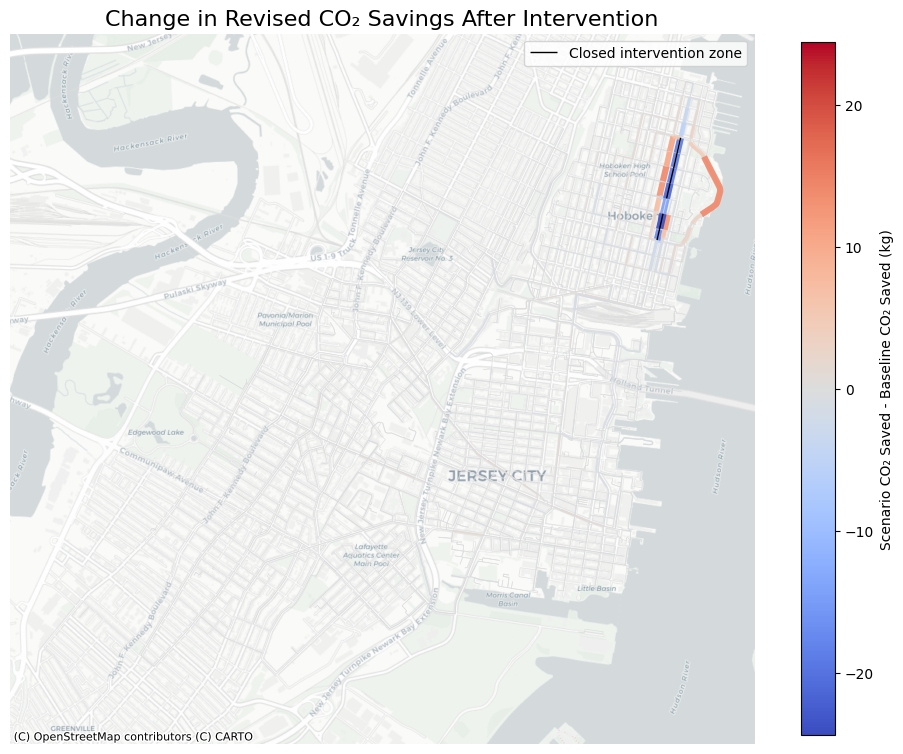

In [49]:
# ----------------------------------------------------
# Step 9F — Plot emissions difference map
# ----------------------------------------------------

from matplotlib.colors import TwoSlopeNorm

emissions_diff_web = emissions_difference_gdf.to_crs(epsg=3857)

# Keep only changed edges for clarity
changed_emissions_web = emissions_diff_web[
    emissions_diff_web["co2_difference_kg"] != 0
].copy()

# Symmetric scale around zero
max_abs_co2_diff = changed_emissions_web["co2_difference_kg"].abs().max()

norm = TwoSlopeNorm(
    vmin=-max_abs_co2_diff,
    vcenter=0,
    vmax=max_abs_co2_diff
)

fig, ax = plt.subplots(figsize=(12, 12))

changed_emissions_web.plot(
    ax=ax,
    column="co2_difference_kg",
    cmap="coolwarm",
    norm=norm,
    linewidth=np.log1p(changed_emissions_web["abs_co2_difference_kg"]) * 1.5 + 0.4,
    alpha=0.9,
    legend=True,
    legend_kwds={
        "label": "Scenario CO₂ Saved - Baseline CO₂ Saved (kg)",
        "shrink": 0.75
    }
)

# Highlight intervention zone
closure_gdf.to_crs(epsg=3857).plot(
    ax=ax,
    color="black",
    linewidth=1,
    label="Closed intervention zone"
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Change in Revised CO₂ Savings After Intervention", fontsize=16)
ax.axis("off")
ax.legend()

plt.show()

### Interpretation

The emissions difference map shows how estimated CO₂ savings changed after the intervention.

The comparison includes 5650 road segments across the baseline and scenario emissions datasets. Out of these, 3944 segments show a decrease in CO₂ savings, 1232 segments show an increase, and 474 segments remain unchanged.

The strongest decrease is approximately -24.40 kg, which occurs on segments that had high baseline CO₂ savings but lost traffic after the closure. This is expected because the selected intervention-zone edges were removed from the scenario network, meaning they no longer receive bicycle flow or contribute to scenario CO₂ savings.

The strongest increase is approximately +14.24 kg, which occurs on alternative routes that gained traffic due to rerouting. These increases show where bicycle traffic shifted after the closure.

Overall, the scenario revised model estimates total CO₂ savings of 4343.72 kg, compared with 4518.61 kg in the baseline revised model. This is a decrease of approximately 174.89 kg, or 3.87%.

This result suggests that the intervention has a measurable but limited environmental impact. The closure reduces estimated CO₂ savings in the intervention zone and shifts some environmental benefit to nearby alternative routes. However, the overall network remains relatively resilient because the total reduction is small compared with the baseline revised CO₂ savings.

The map should therefore be interpreted as evidence of localized redistribution rather than a major system-wide emissions change.

### Main Findings

The intervention did not disconnect the cycling network. All **10,000 baseline routes** and all **10,000 scenario routes** were successfully computed, with **0 failed routes** in both cases.

The average route length increased only slightly, from approximately **1616.67 m** in the baseline case to **1623.24 m** in the scenario case. This represents an average increase of about **6.58 m**, or **0.53%**.

This suggests that the wider cycling network is relatively resilient to this localized closure. Most routes were not affected, as shown by the median route length difference of **0 m**. However, a small subset of trips experienced larger detours, with the maximum route length increase reaching approximately **429.72 m**.

The flow comparison showed that:

- **77 edges lost traffic**,
- **104 edges gained traffic**,
- and **3312 edges remained unchanged**.

This confirms that the intervention caused localized rerouting rather than a large system-wide redistribution.

### Policy and Planning Insights

The scenario results suggest that the selected intervention zone plays an important local role in the cycling network.

Although the wider network remained connected, the closure shifted bicycle traffic to nearby alternative routes. This means that even small localized interventions can affect how cyclists distribute across surrounding streets.

From a planning perspective, this has several implications:

1. Maintain alternative routes during closures  
   Since some cyclists are rerouted when a high-impact corridor is closed, nearby parallel or connecting streets should remain safe and accessible.

2. Provide temporary cycling infrastructure during roadworks  
   If this type of closure occurs due to construction or street redesign, temporary protected cycling lanes, clear signage, and safe detour guidance should be provided.

3. Monitor nearby streets that gain traffic  
   Roads that gained bicycle traffic after the intervention may require additional safety treatments, especially if they are not designed for higher cycling volumes.

4. Avoid evaluating interventions only at the closure location  
   The difference maps show that impacts spread to nearby alternative routes. Therefore, planning analysis should consider the surrounding network, not only the closed segment.

5. Use flow and emissions together  
   Traffic flow maps show where cycling demand changes, while emissions modelling shows how those changes affect environmental benefits. Combining both gives a more complete understanding of intervention impacts.

### Recommended Intervention Proposal

If a similar closure or redesign were implemented in reality, the recommended planning approach would be:

- keep the closure limited in duration or provide a clear cycling detour,
- prioritize nearby streets that gained scenario traffic for temporary safety improvements,
- add signage and wayfinding before cyclists reach the closed zone,
- protect junctions where rerouted cyclists merge with alternative corridors,
- and monitor post-intervention cycling volumes to check whether the modelled redistribution matches real behavior.

The goal should not only be to close or redesign the selected corridor, but to manage the surrounding cycling network so that access, safety, and environmental benefits are maintained.

### Limitations

This scenario modelling approach has several limitations.

First, the analysis uses a representative routing sample rather than routing every trip in the full dataset. This keeps the computation manageable, but it means the results represent sampled routing behavior rather than the complete trip population.

Second, shortest-path routing is used. In reality, cyclists may choose routes based on safety, comfort, slope, traffic stress, bike-lane availability, or personal preference, not only distance.

Third, the scenario removes selected OSM edges completely. Real-world interventions may still allow partial access, temporary cycling detours, or one-way movement.

Fourth, the emissions model estimates avoided motor-vehicle emissions from bicycle trips. It assumes that bicycle trips could replace motorized trips, but in reality some trips may replace walking, public transport, or trips that would not have occurred.

Fifth, the revised emissions model uses road attributes and adjustment factors as proxies. These improve realism compared with a constant emission factor, but they are still simplified assumptions rather than measured emissions.

Therefore, the results should be interpreted as a scenario-based estimate of likely impacts, not as a precise prediction of real-world behavior.

### Final Conclusion

This scenario modelling task tested how the closure of a high-impact cycling intervention zone affects route choice, traffic flows, and estimated CO₂ savings.

The results show that the network remains connected and broadly resilient. The average route length increased only slightly, and most routes were unaffected. However, the intervention caused measurable local redistribution, with some nearby segments losing traffic and others gaining traffic.

The emissions comparison showed that the scenario reduced revised estimated CO₂ savings from 4518.61 kg to 4343.72 kg, a decrease of approximately 3.87%.

Overall, the intervention has a limited network-wide impact but a clear localized effect. This suggests that small corridor closures in dense urban cycling networks may be manageable, but they should be supported by safe alternative routes, temporary cycling infrastructure, and careful monitoring of streets that receive additional bicycle traffic.

The analysis demonstrates how routing, traffic flow modelling, and emissions modelling can be combined to evaluate mobility interventions from both transport and environmental perspectives.